# 04 SRC Joint Physics and Hyperparameter Optimization

**Scientific question.** Which configuration wins the predeclared guarded objective?

**Learning objectives.** Audit selection, feature cost, sensitivity and measured competing objectives.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Joint search and the guard

This record has densely overlapping sampled histories. Each test block
$[a,b)$ has a 1,792-sample fit exclusion before and after the block. Start
fresh feature states inside the retained fit segments. Stage-specific
designs screen coherent physical groups, nonlinear width, proxy history,
solver/penalty, compactness, and adapter choices. Inspect the actual
configuration and objective weights before interpreting the incumbent.

A pure-MSE setting, a bounded compact setting, and an objective-ranked
setting can differ. Compare their clean fold, perturbation and pulse
evidence. Companion Chapters 6, 15, and 16 explain rank provenance.

With mean nominal error $C$, mean RPM-perturbed error $S$, mean pulse
distortion $D$, and learned-parameter count $p$, the recorded utility is
$J=C+0.14\max(0,S-C)+0.009D+0.000002p$. Here $C$ and $S$ use squared
standardized vibration units. $D$ is a dimensionless prediction-energy
ratio to which the specified coefficient assigns an empirical error
penalty. The positive part keeps an incidental stress improvement from
paying for added instability elsewhere. All four weights or terms are
part of the configuration contract. Feature count is distinct from
parameter count because the innovation fit has its own coefficients.
No value from the eventual development record appears in $J$.

In [2]:
trials = table("results/optimization/trials.csv")
folds = table("results/optimization/fold_scores.csv")
selected = evidence("results/optimization/selected_configs.json")
if selected:
    print("Recorded optimization protocol")
    display(selected["protocol"])
    display(pd.DataFrame(selected["selection"]).drop(columns="config",errors="ignore"))
if trials is not None:
    display(trials.groupby(["stage","status"]).size().to_frame("Trials"))
    good = trials.loc[trials.status.eq("DONE")]
    if len(good):
        fields = ["trial_id","stage","fold_mse","fold_stress_mse","fold_pulse_distortion",
                  "utility","parameters"]
        display(good.sort_values("utility")[fields].head(8))

Recorded optimization protocol


{'version': 1,
 'folds': [[4800, 7200], [11200, 13600], [18400, 20800]],
 'guard_samples': 1792,
 'seed': 19,
 'speed_bias_fraction': 0.012,
 'pulse_amplitude': 0.6,
 'stress_excess_weight': 0.14,
 'pulse_distortion_weight': 0.009,
 'per_coefficient_penalty': 2e-06,
 'compact_fraction': 0.65}

,trial_id,stage,utility,fold_mse,fold_stress_mse,fold_pulse_distortion,parameters,model
0,selected_correction,E,0.371689,0.355734,0.381362,1.050501,1456,primary_pi_src
1,local_ridge_down,E,0.372125,0.355511,0.380581,1.132523,1456,pi_src_pure_mse
2,lag_degree1,B,0.389832,0.376050,0.402773,0.930360,834,pi_src_compact
3,selected_uncorrected,E,0.371901,0.355942,0.381616,1.050319,1456,pi_src_optimized


,,Trials
stage,status,
A,DONE,13
B,DONE,13
C,DONE,5
D,DONE,6
E,DONE,4


,trial_id,stage,fold_mse,fold_stress_mse,fold_pulse_distortion,utility,parameters
40,selected_correction,E,0.355734,0.381362,1.050501,0.371689,1456
35,protected_four,D,0.355787,0.381417,1.050634,0.371742,1456
39,selected_uncorrected,E,0.355942,0.381616,1.050319,0.371901,1456
37,local_ridge_down,E,0.355511,0.380581,1.132523,0.372125,1456
38,local_ridge_up,E,0.359086,0.384913,0.933341,0.374014,1456
30,six_wide,C,0.358724,0.400281,1.066378,0.376951,1406
34,corr_long,D,0.366233,0.393857,1.092969,0.382029,1046
9,order12,A,0.368360,0.394741,1.052647,0.383835,1154


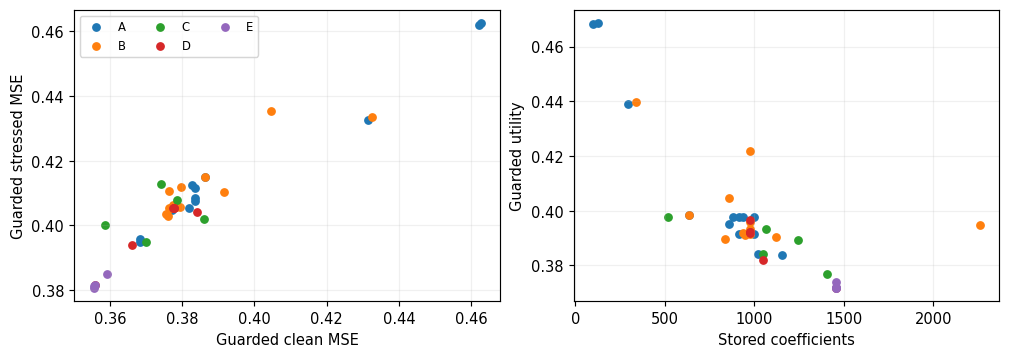

,trial_id,lo,hi,mse,stress_mse,history,solver,condition,fit_rows
105,protected_four,4800,7200,0.293865,0.324419,1536,cholesky,26272.382665,16992
106,protected_four,11200,13600,0.424080,0.440246,1536,cholesky,16516.860649,16992
107,protected_four,18400,20800,0.349414,0.379584,1536,cholesky,25360.052766,16992
111,local_ridge_down,4800,7200,0.297507,0.326943,1536,cholesky,57941.778537,16992
112,local_ridge_down,11200,13600,0.423554,0.439507,1536,cholesky,35696.683741,16992
113,local_ridge_down,18400,20800,0.345471,0.375294,1536,cholesky,54839.394838,16992
117,selected_uncorrected,4800,7200,0.293627,0.324165,512,cholesky,26272.382665,16992
118,selected_uncorrected,11200,13600,0.423914,0.440016,512,cholesky,16516.860649,16992
119,selected_uncorrected,18400,20800,0.350285,0.380666,512,cholesky,25360.052766,16992
120,selected_correction,4800,7200,0.293951,0.324512,1280,cholesky,26272.382665,16992


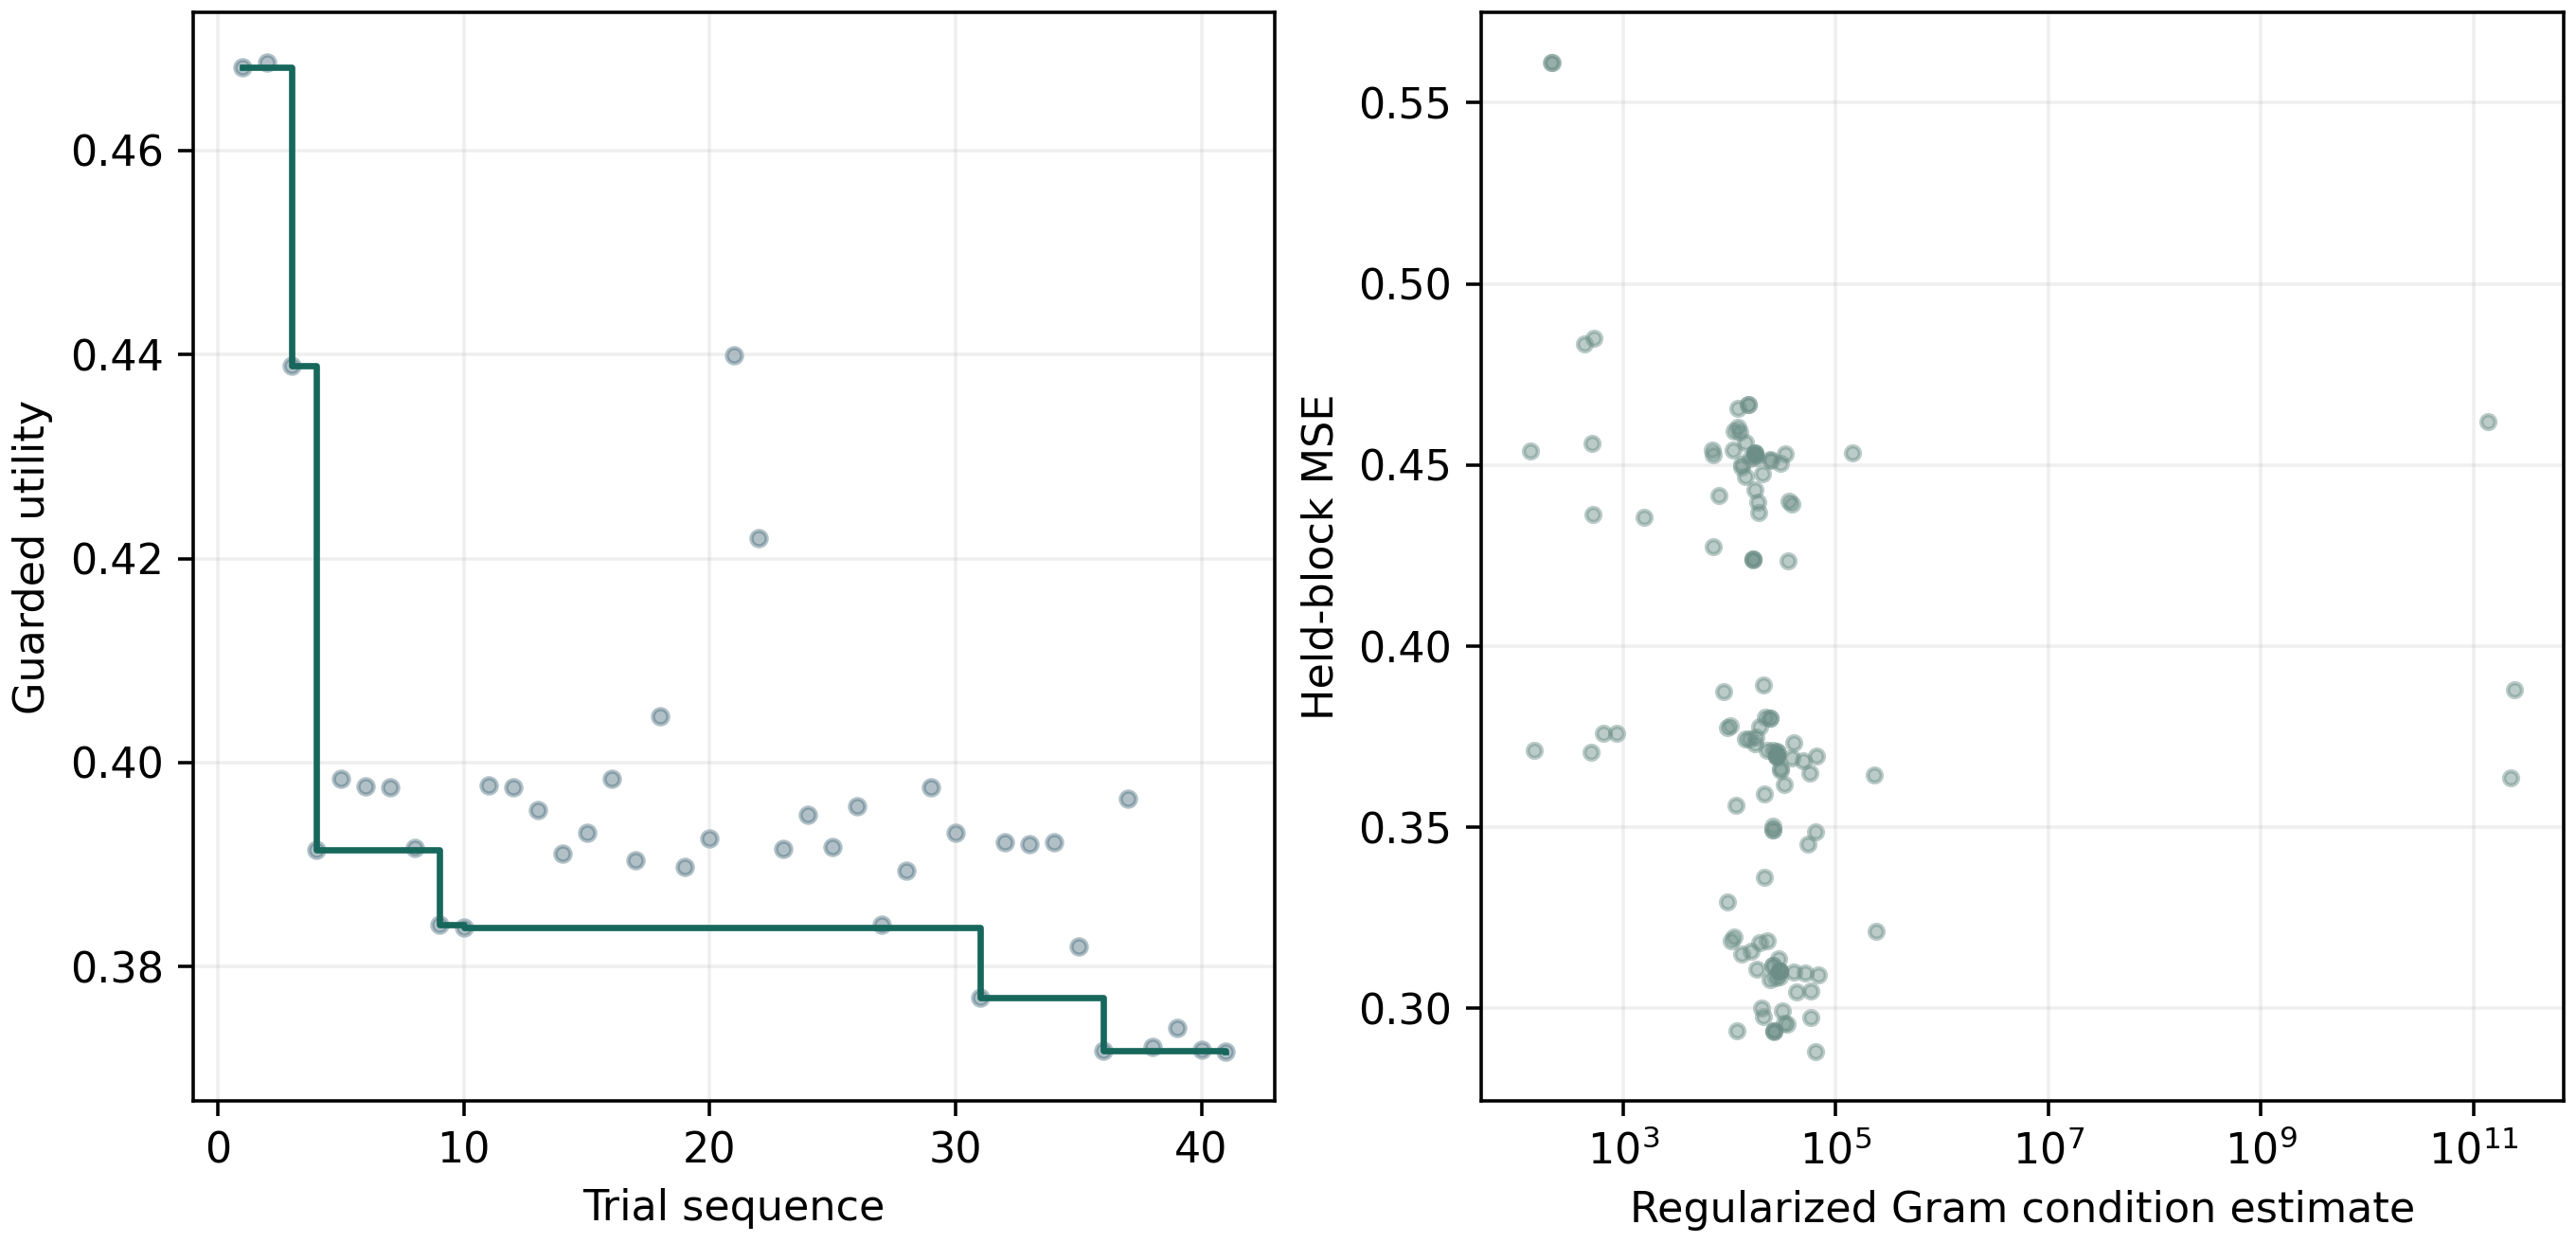

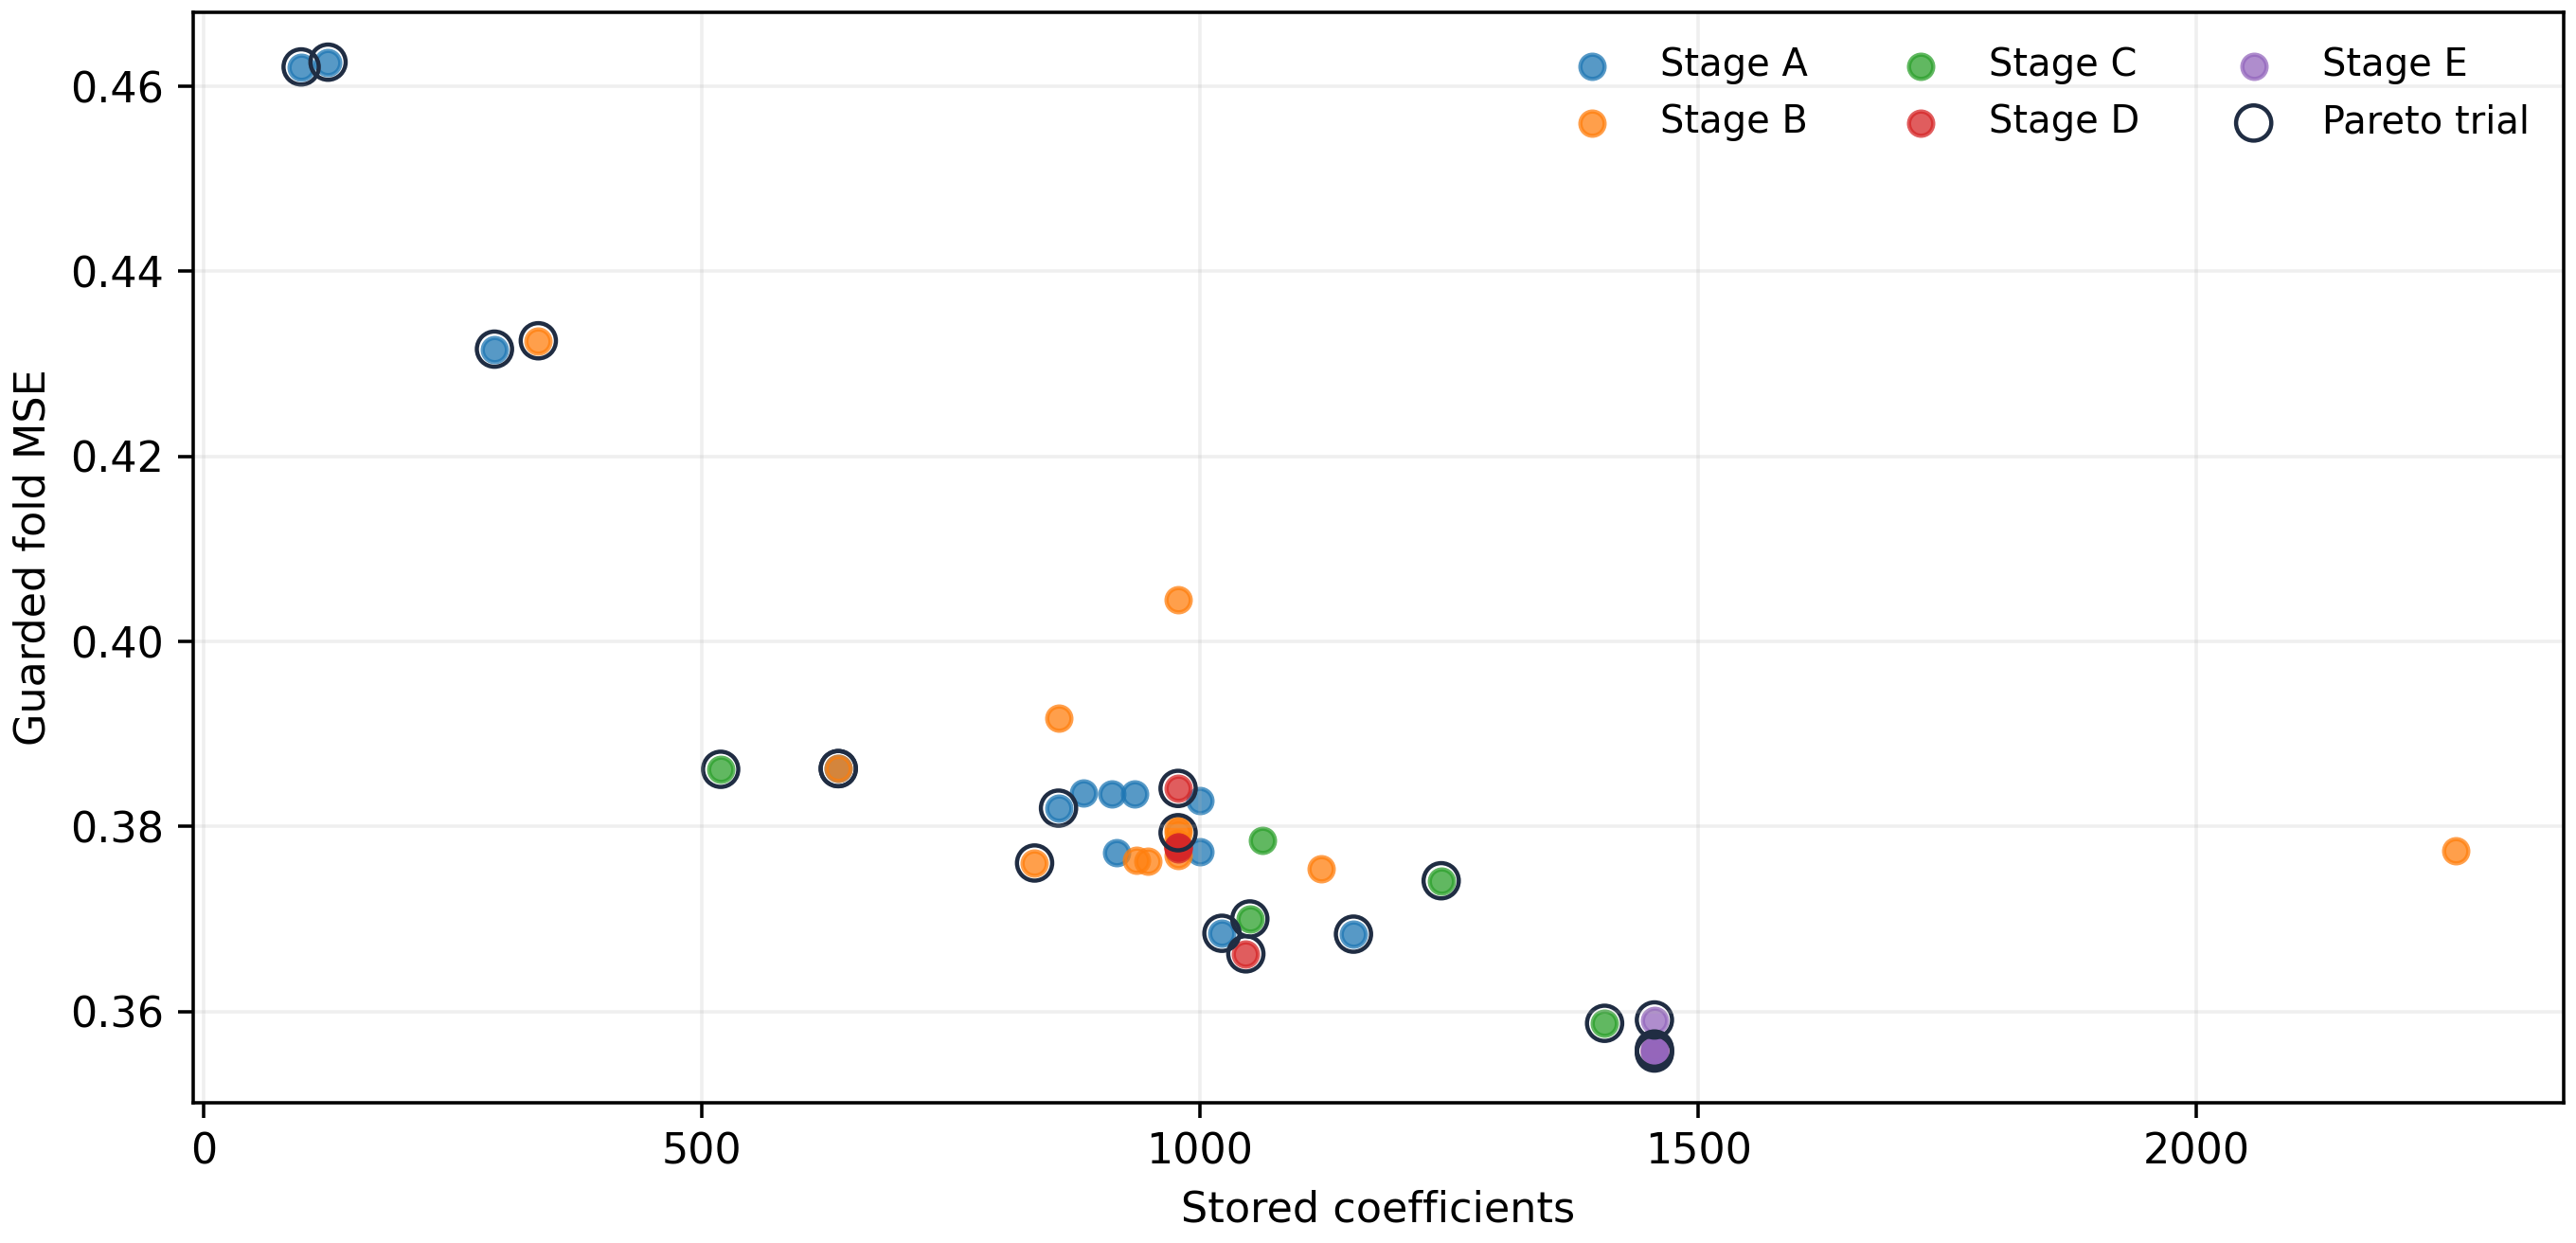

,trial_id,stage,fold_mse,fold_stress_mse,fold_pulse_distortion,parameters
0,selected_correction,E,0.355734,0.381362,1.050501,1456
1,selected_uncorrected,E,0.355942,0.381616,1.050319,1456
2,local_ridge_down,E,0.355511,0.380581,1.132523,1456
3,local_ridge_up,E,0.359086,0.384913,0.933341,1456
4,six_wide,C,0.358724,0.400281,1.066378,1406
5,corr_long,D,0.366233,0.393857,1.092969,1046
6,order12,A,0.368360,0.394741,1.052647,1154
7,order6,A,0.368454,0.395915,1.087430,1022
8,short,C,0.370002,0.394732,0.953650,1050
9,long,C,0.374133,0.412687,0.823185,1242


In [3]:
if trials is not None and len(good):
    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3), layout="constrained")
    for stage, group in good.groupby("stage"):
        ax[0].scatter(group.fold_mse, group.fold_stress_mse, label=stage, s=25)
        ax[1].scatter(group.parameters, group.utility, label=stage, s=25)
    ax[0].set(xlabel="Guarded clean MSE", ylabel="Guarded stressed MSE")
    ax[1].set(xlabel="Stored coefficients", ylabel="Guarded utility")
    ax[0].legend(ncol=3, fontsize=8)
    plt.show()
if folds is not None:
    fields = ["trial_id","lo","hi","mse","stress_mse","history","solver","condition","fit_rows"]
    display(folds.loc[folds.trial_id.isin(good.nsmallest(4,"utility").trial_id),fields])
show_fig("figures/optimization/selection_history.png")
show_fig("figures/optimization/guarded_frontier.png")
pareto = table("results/optimization/pareto_front.csv")
if pareto is not None:
    display(pareto[[k for k in ["trial_id","stage","fold_mse","fold_stress_mse",
                                "fold_pulse_distortion","parameters"] if k in pareto]].head(10))

In [4]:
if selected and trials is not None:
    protocol = selected["protocol"]
    done = trials.loc[trials.status.eq("DONE")]
    recomputed = (
        done.fold_mse
        + protocol["stress_excess_weight"] * (done.fold_stress_mse-done.fold_mse).clip(lower=0)
        + protocol["pulse_distortion_weight"] * done.fold_pulse_distortion
        + protocol["per_coefficient_penalty"] * done.parameters
    )
    np.testing.assert_allclose(done.utility,recomputed,atol=1e-12,rtol=0)
    for item in selected["selection"]:
        chosen = done.loc[done.trial_id.eq(item["trial_id"])].iloc[0]
        np.testing.assert_allclose(chosen.fold_mse,item["fold_mse"],rtol=0,atol=1e-12)
        print(item["model"], item["trial_id"], f"utility = {chosen.utility:.6f}")

primary_pi_src selected_correction utility = 0.371689
pi_src_pure_mse local_ridge_down utility = 0.372125
pi_src_compact lag_degree1 utility = 0.389832
pi_src_optimized selected_uncorrected utility = 0.371901


Conditioning and solver status come from individual training fits.
A broad oscillator bank can provide useful coverage and still add correlated
columns. The optimized main and clean-MSE alternatives compare objective
definitions fixed before development scoring. The Pareto frontier shows
settings that avoid simultaneous domination across the measured criteria.

### Interpretation and limits

The best trial is relative to this schedule and its utility. Inspect fold
variation, columns, and objective terms before treating small ranking
changes as robust. An alternative with better supplied development MSE is
a descriptive result. It does not reopen the guarded choice.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).